# 03 Erregresioa: hurrengo orduko NO2a

Barakaldon hurrengo orduko NO2a (µg/m³) iragarri nahi dugu. EDAn ikusi genuen NO2a dela seriarik garbiena eta eredu argienak dituena. PIAko datuak eta Pipeline-a erabiltzen ditugu.

Ereduak: erregresio lineal sinplea eta anizkoitza, Ridge eta Lasso, eta Random Forest erreferentzia gisa. Amaieran gauza bera egiten dugu PM10 eta PM2.5ekin.

Metrikak: MAE (batez beste zenbat µg/m³ huts egiten dugun), RMSE (errore handiak gehiago zigortzen ditu) eta R² (aldakuntzaren zein zati azaltzen den).

In [1]:
# Liburutegiak
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.path.append("../src")
from aurreprozesamendua import ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK, ERREGRESIO_HELBURUA, KUTSATZAILE_HELBURUAK, aurreprozesadorea_sortu

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Datuak eta balioztapena

2023-2025 entrenatzeko eta hiperparametroak aukeratzeko, eta 2026 amaieran probatzeko. Gaian KFold erabiltzen da balioztapen gurutzaturako, baina denbora-serie batean orduak nahasteak tranpa egiten du; horregatik TimeSeriesSplit erabiltzen dugu: iraganarekin entrenatu eta hurrengo aldiarekin balioztatu.

In [2]:
entrenamendua = pd.read_csv("../data/prozesatuak/barakaldo_entrenamendua.csv", index_col="data", parse_dates=True)
proba = pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data", parse_dates=True)

ALDAGAIAK = ALDAGAI_NUMERIKOAK + ALDAGAI_KATEGORIKOAK
X_entr = entrenamendua[ALDAGAIAK]
X_proba = proba[ALDAGAIAK]
y_entr = entrenamendua[ERREGRESIO_HELBURUA]
y_proba = proba[ERREGRESIO_HELBURUA]

print("Entrenamendua:", X_entr.shape, "| Proba:", X_proba.shape)
print("Sarrerako aldagaiak:", len(ALDAGAIAK))

Entrenamendua: (26039, 18) | Proba: (7253, 18)
Sarrerako aldagaiak: 18


In [3]:
# Denborazko balioztapen gurutzatua 5 zatiketarekin
balioztapena = TimeSeriesSplit(n_splits=5)

for i, (entr_indizeak, bal_indizeak) in enumerate(balioztapena.split(X_entr)):
    print("Zatiketa", i + 1,
          "| entrenatzen du:", entrenamendua.index[entr_indizeak[0]].date(), "-", entrenamendua.index[entr_indizeak[-1]].date(),
          "| balioztatzen du:", entrenamendua.index[bal_indizeak[0]].date(), "-", entrenamendua.index[bal_indizeak[-1]].date())

Zatiketa 1 | entrenatzen du: 2023-01-01 - 2023-07-05 | balioztatzen du: 2023-07-05 - 2024-01-03
Zatiketa 2 | entrenatzen du: 2023-01-01 - 2024-01-03 | balioztatzen du: 2024-01-03 - 2024-07-04
Zatiketa 3 | entrenatzen du: 2023-01-01 - 2024-07-04 | balioztatzen du: 2024-07-04 - 2025-01-02
Zatiketa 4 | entrenatzen du: 2023-01-01 - 2025-01-02 | balioztatzen du: 2025-01-02 - 2025-07-02
Zatiketa 5 | entrenatzen du: 2023-01-01 - 2025-07-02 | balioztatzen du: 2025-07-02 - 2026-01-01


In [4]:
# Hiru metrikak batera kalkulatzeko funtzioa
def metrikak(y_benetakoa, y_iragarria):
    mae = mean_absolute_error(y_benetakoa, y_iragarria)
    rmse = float(np.sqrt(mean_squared_error(y_benetakoa, y_iragarria)))
    r2 = r2_score(y_benetakoa, y_iragarria)
    return round(mae, 3), round(rmse, 3), round(r2, 3)

# Hemen gordeko ditugu eredu bakoitzaren emaitzak
emaitzak = []

### Erreferentzia: iraunkortasuna

Ezer entrenatu aurretik, eredu "tonto" bat: hurrengo orduko NO2a oraingoa izango da. Eredu batek hau hobetzen ez badu, ez du ezertarako balio.

In [5]:
iraunkortasun_iragarpena = proba["NO2"].fillna(entrenamendua["NO2"].median())
mae, rmse, r2 = metrikak(y_proba, iraunkortasun_iragarpena)
emaitzak.append(["Iraunkortasuna (baseline)", np.nan, mae, rmse, r2])
print("Iraunkortasuna -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

Iraunkortasuna -> MAE: 4.554 | RMSE: 7.01 | R2: 0.712


## 2. Erregresio lineal sinplea

Aldagai bakarra, helburuarekin korrelazio handiena duena.

In [6]:
korrelazioak = entrenamendua[ALDAGAI_NUMERIKOAK].corrwith(y_entr).abs().sort_values(ascending=False)
korrelazioak.head(8).round(3)

NO2               0.876
NO2_duela_1h      0.717
NO2_batez_24h     0.534
NO                0.471
CO                0.462
NO2_duela_24h     0.390
haize_abiadura    0.378
SO2               0.291
dtype: float64

In [7]:
# Korrelazio handiena duen aldagaia uneko NO2a da
eredu_sinplea = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(["NO2"], [])),
    ("eredua", LinearRegression()),
])

cv_sinplea = cross_validate(eredu_sinplea, entrenamendua[["NO2"]], y_entr, cv=balioztapena, scoring="neg_mean_absolute_error")
eredu_sinplea.fit(entrenamendua[["NO2"]], y_entr)
iragarpen_sinplea = eredu_sinplea.predict(proba[["NO2"]])

mae, rmse, r2 = metrikak(y_proba, iragarpen_sinplea)
emaitzak.append(["Lineal sinplea (uneko NO2a)", -cv_sinplea["test_score"].mean(), mae, rmse, r2])
print("Balioztapeneko MAE:", round(-cv_sinplea["test_score"].mean(), 3))
print("Proba -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

Balioztapeneko MAE: 4.282
Proba -> MAE: 4.523 | RMSE: 6.761 | R2: 0.732


NO2_hurrengoa = 2.31 + 0.876 x uneko_NO2


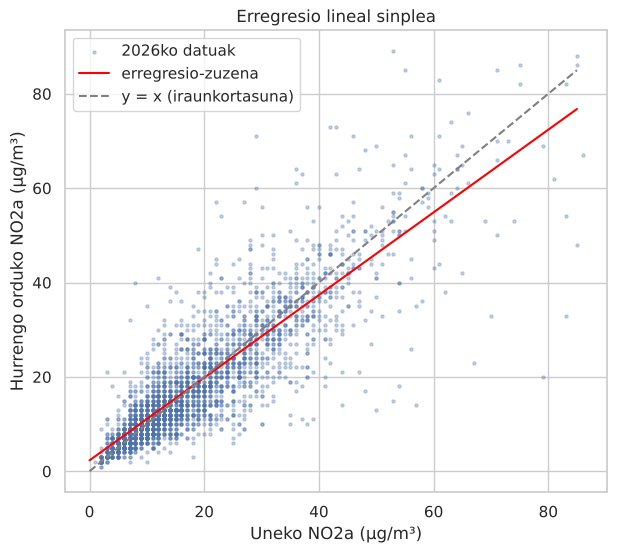

In [8]:
# Erregresio-zuzena jatorrizko unitateetan (estandarizatu gabe)
zuzena = LinearRegression().fit(entrenamendua[["NO2"]].fillna(entrenamendua["NO2"].median()), y_entr)
print("NO2_hurrengoa = {:.2f} + {:.3f} x uneko_NO2".format(zuzena.intercept_, zuzena.coef_[0]))

lagina = proba.sample(3000, random_state=42)
plt.figure(figsize=(7, 6))
plt.scatter(lagina["NO2"], lagina[ERREGRESIO_HELBURUA], s=5, alpha=0.3, label="2026ko datuak")
x = np.linspace(0, 85, 100)
plt.plot(x, zuzena.intercept_ + zuzena.coef_[0] * x, color="red", label="erregresio-zuzena")
plt.plot(x, x, color="gray", linestyle="--", label="y = x (iraunkortasuna)")
plt.xlabel("Uneko NO2a (µg/m³)")
plt.ylabel("Hurrengo orduko NO2a (µg/m³)")
plt.title("Erregresio lineal sinplea")
plt.legend()
plt.show()

Zuzenaren malda 1 baino txikiagoa da (0,88): NO2a altu dagoenean apur bat jaistea espero du, eta baxu dagoenean igotzea. Aldagai bakarrarekin R² 0,73 da, baina ia ez du iraunkortasuna hobetzen (MAE 4,52 eta 4,55).

## 3. Erregresio lineal anizkoitza

18 aldagaiak erabiltzen ditugu (65 zutabe one-hot-en ondoren).

In [9]:
eredu_anizkoitza = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", LinearRegression()),
])

cv_anizkoitza = cross_validate(eredu_anizkoitza, X_entr, y_entr, cv=balioztapena, scoring="neg_mean_absolute_error")
eredu_anizkoitza.fit(X_entr, y_entr)

entr_iragarpena = eredu_anizkoitza.predict(X_entr)
iragarpen_anizkoitza = eredu_anizkoitza.predict(X_proba)

mae, rmse, r2 = metrikak(y_proba, iragarpen_anizkoitza)
emaitzak.append(["Lineal anizkoitza", -cv_anizkoitza["test_score"].mean(), mae, rmse, r2])

print("Balioztapeneko MAE:", round(-cv_anizkoitza["test_score"].mean(), 3))
print("Entrenamendua -> MAE, RMSE, R2:", metrikak(y_entr, entr_iragarpena))
print("Proba         -> MAE, RMSE, R2:", (mae, rmse, r2))

Balioztapeneko MAE: 4.012
Entrenamendua -> MAE, RMSE, R2: (3.948, 5.734, 0.804)
Proba         -> MAE, RMSE, R2: (4.263, 6.314, 0.766)


Entrenamenduan eta proban antzeko emaitzak ditu (R² 0,80 eta 0,77), beraz ez dago gaindoitzerik.

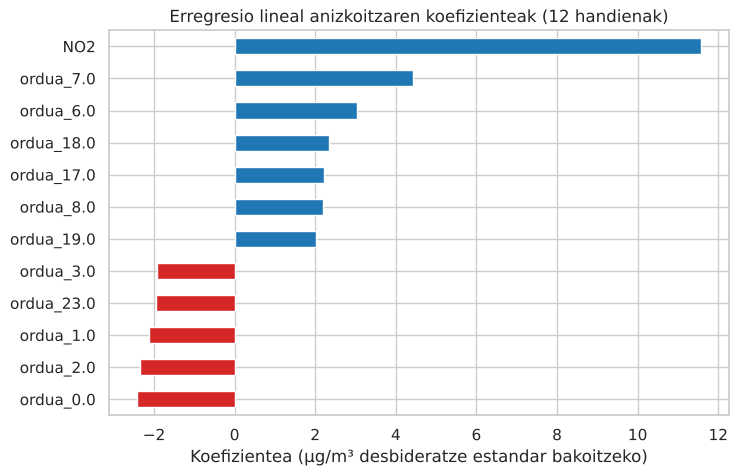

In [10]:
# Koefiziente garrantzitsuenak (aldagaiak estandarizatuta daude, beraz alderatu daitezke)
izenak = eredu_anizkoitza.named_steps["aurreprozesamendua"].named_steps["eraldatu"].get_feature_names_out()
izenak = [n.split("__")[1] for n in izenak]
koefizienteak = pd.Series(eredu_anizkoitza.named_steps["eredua"].coef_, index=izenak)
handienak = koefizienteak.reindex(koefizienteak.abs().sort_values(ascending=False).index).head(12)

handienak.sort_values().plot(kind="barh", figsize=(8, 5), color=["tab:red" if k < 0 else "tab:blue" for k in handienak.sort_values()])
plt.title("Erregresio lineal anizkoitzaren koefizienteak (12 handienak)")
plt.xlabel("Koefizientea (µg/m³ desbideratze estandar bakoitzeko)")
plt.show()

#### Koefizienteak

- Uneko NO2a da garrantzitsuena alde handiz.
- Orduek eragin handia dute: goizeko 6:00-8:00ak eta arratsaldeko 17:00-20:00ak igotzen dute NO2a (trafikoa), eta gaueko orduek jaitsi.
- Larunbatak eta igandeak NO2a jaisten dute, eta haizeak ere bai.
- Aurreko orduko NO2ak koefiziente negatiboa du: bat-batean igo bada, ereduak ez du espero berdin jarraitzea.

## 4. Ridge (L2)

Koefiziente handiak zigortzen ditu (alpha), gaindoitzea saihesteko eta aldagai oso lotuak daudenean laguntzeko. Alpha GridSearchCV-rekin aukeratzen dugu.

In [11]:
ridge_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", Ridge()),
])
ridge_alpha_balioak = [0.01, 0.1, 1, 10, 100, 1000, 10000]

ridge_bilaketa = GridSearchCV(ridge_eredua, {"eredua__alpha": ridge_alpha_balioak},
                              cv=balioztapena, scoring="neg_mean_absolute_error")
ridge_bilaketa.fit(X_entr, y_entr)

ridge_iragarpena = ridge_bilaketa.predict(X_proba)
mae, rmse, r2 = metrikak(y_proba, ridge_iragarpena)
emaitzak.append(["Ridge (alpha=" + str(ridge_bilaketa.best_params_["eredua__alpha"]) + ")",
                 -ridge_bilaketa.best_score_, mae, rmse, r2])

print("Alpha onena:", ridge_bilaketa.best_params_["eredua__alpha"])
print("Balioztapeneko MAE:", round(-ridge_bilaketa.best_score_, 3))
print("Proba -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

Alpha onena: 100
Balioztapeneko MAE: 3.985
Proba -> MAE: 4.255 | RMSE: 6.315 | R2: 0.766


## 5. Lasso (L1)

Lassok ere koefizienteak zigortzen ditu, baina batzuk zehazki 0an utz ditzake: aldagaiak berak hautatzen ditu.

In [12]:
lasso_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", Lasso(max_iter=10000)),
])
lasso_alpha_balioak = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2]

lasso_bilaketa = GridSearchCV(lasso_eredua, {"eredua__alpha": lasso_alpha_balioak},
                              cv=balioztapena, scoring="neg_mean_absolute_error")
lasso_bilaketa.fit(X_entr, y_entr)

lasso_iragarpena = lasso_bilaketa.predict(X_proba)
mae, rmse, r2 = metrikak(y_proba, lasso_iragarpena)
emaitzak.append(["Lasso (alpha=" + str(lasso_bilaketa.best_params_["eredua__alpha"]) + ")",
                 -lasso_bilaketa.best_score_, mae, rmse, r2])

print("Alpha onena:", lasso_bilaketa.best_params_["eredua__alpha"])
print("Balioztapeneko MAE:", round(-lasso_bilaketa.best_score_, 3))
print("Proba -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

Alpha onena: 0.01
Balioztapeneko MAE: 3.977
Proba -> MAE: 4.242 | RMSE: 6.314 | R2: 0.766


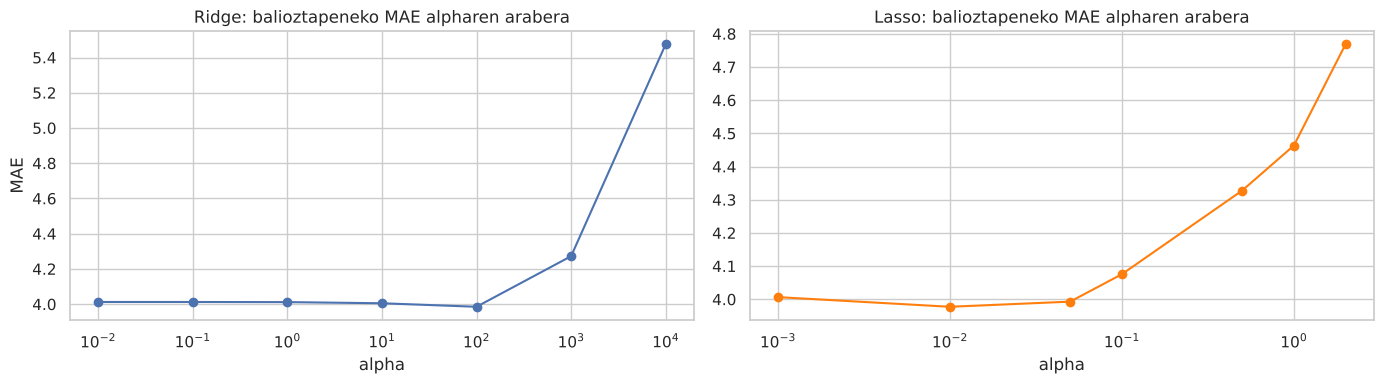

In [13]:
# Alpharen eragina balioztapen-errorean
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
ardatzak[0].plot(ridge_alpha_balioak, -ridge_bilaketa.cv_results_["mean_test_score"], marker="o")
ardatzak[0].set_xscale("log")
ardatzak[0].set_title("Ridge: balioztapeneko MAE alpharen arabera")
ardatzak[0].set_xlabel("alpha")
ardatzak[0].set_ylabel("MAE")
ardatzak[1].plot(lasso_alpha_balioak, -lasso_bilaketa.cv_results_["mean_test_score"], marker="o", color="tab:orange")
ardatzak[1].set_xscale("log")
ardatzak[1].set_title("Lasso: balioztapeneko MAE alpharen arabera")
ardatzak[1].set_xlabel("alpha")
plt.tight_layout()
plt.show()

In [14]:
# Lassok ezabatutako aldagaiak (koefizientea = 0)
lasso_onena = lasso_bilaketa.best_estimator_
lasso_koef = pd.Series(lasso_onena.named_steps["eredua"].coef_, index=izenak)

print("Zutabeak guztira:", len(lasso_koef))
print("Lassok ezabatutako zutabeak:", (lasso_koef == 0).sum())
print("Geratzen diren zutabeak:", (lasso_koef != 0).sum())
print()
print("Ezabatuak:", list(lasso_koef[lasso_koef == 0].index))
print()
print("Geratzen direnak:")
print(lasso_koef[lasso_koef != 0].sort_values(key=abs, ascending=False).round(3))

Zutabeak guztira: 65
Lassok ezabatutako zutabeak: 14
Geratzen diren zutabeak: 51

Ezabatuak: ['PM10_batez_24h', 'ordua_9.0', 'ordua_15.0', 'ordua_22.0', 'aste_eguna_2.0', 'aste_eguna_3.0', 'aste_eguna_4.0', 'hilabetea_3.0', 'hilabetea_5.0', 'hilabetea_6.0', 'hilabetea_9.0', 'hilabetea_11.0', 'haize_sektorea_0.0', 'haize_sektorea_5.0']

Geratzen direnak:
NO2                   11.699
ordua_7.0              4.575
ordua_6.0              3.200
ordua_18.0             2.400
ordua_8.0              2.302
ordua_17.0             2.290
ordua_19.0             2.050
NO2_duela_1h          -1.896
ordua_20.0             1.788
ordua_0.0             -1.767
ordua_2.0             -1.677
ordua_1.0             -1.447
ordua_23.0            -1.348
ordua_10.0            -1.253
ordua_3.0             -1.233
ordua_21.0             1.044
ordua_11.0            -1.039
ordua_5.0              1.020
ordua_12.0            -0.945
aste_eguna_6.0        -0.922
ordua_16.0             0.911
NO2_batez_24h          0.782
haize_

#### Erregularizazioaren ondorioak

- Ridgek ia ez du ezer aldatzen (alpha = 100 izanda ere): ez zegoen gaindoitzerik zuzentzeko.
- Lassok du balioztapeneko errore onena (3,98) eta 65 zutabeetatik 14 kentzen ditu: hilabete batzuk, asteko egun batzuk, ordu batzuk eta 24 orduko PM10a. NO2a iragartzeko garrantzitsuena azken NO2a, ordua, asteburua eta haizea dira.

## 6. Erreferentzia ez-lineala: Random Forest

Eredu lineal bat erabiltzeagatik zenbat galtzen dugun ikusteko. Ez dugu doitzen, alderatzeko bakarrik da.

In [15]:
rf_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)),
])

hasiera = time.time()
rf_eredua.fit(X_entr, y_entr)
print("Entrenamendu-denbora:", round(time.time() - hasiera, 1), "s")

rf_iragarpena = rf_eredua.predict(X_proba)
mae, rmse, r2 = metrikak(y_proba, rf_iragarpena)
emaitzak.append(["Gehigarria: Random Forest", np.nan, mae, rmse, r2])
print("Proba -> MAE:", mae, "| RMSE:", rmse, "| R2:", r2)

Entrenamendu-denbora: 19.0 s
Proba -> MAE: 4.209 | RMSE: 6.372 | R2: 0.762


## 7. Ereduen alderaketa

In [16]:
taula = pd.DataFrame(emaitzak, columns=["eredua", "balioztapen MAE", "proba MAE", "proba RMSE", "proba R2"])
taula.round(3)

,eredua,balioztapen MAE,proba MAE,proba RMSE,proba R2
0,Iraunkortasuna (baseline),NaN,4.554,7.010,0.712
1,Lineal sinplea (uneko NO2a),4.282,4.523,6.761,0.732
2,Lineal anizkoitza,4.012,4.263,6.314,0.766
3,Ridge (alpha=100),3.985,4.255,6.315,0.766
4,Lasso (alpha=0.01),3.977,4.242,6.314,0.766
5,Gehigarria: Random Forest,NaN,4.209,6.372,0.762


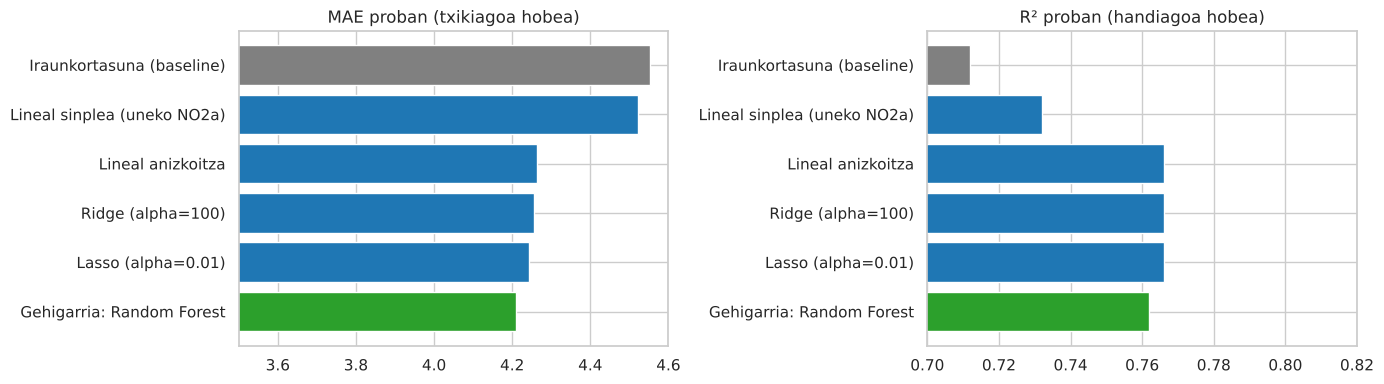

In [17]:
fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
koloreak = ["gray", "tab:blue", "tab:blue", "tab:blue", "tab:blue", "tab:green"]
ardatzak[0].barh(taula["eredua"], taula["proba MAE"], color=koloreak)
ardatzak[0].set_title("MAE proban (txikiagoa hobea)")
ardatzak[0].set_xlim(3.5, 4.6)
ardatzak[0].invert_yaxis()
ardatzak[1].barh(taula["eredua"], taula["proba R2"], color=koloreak)
ardatzak[1].set_title("R² proban (handiagoa hobea)")
ardatzak[1].set_xlim(0.7, 0.82)
ardatzak[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Erroreen analisia

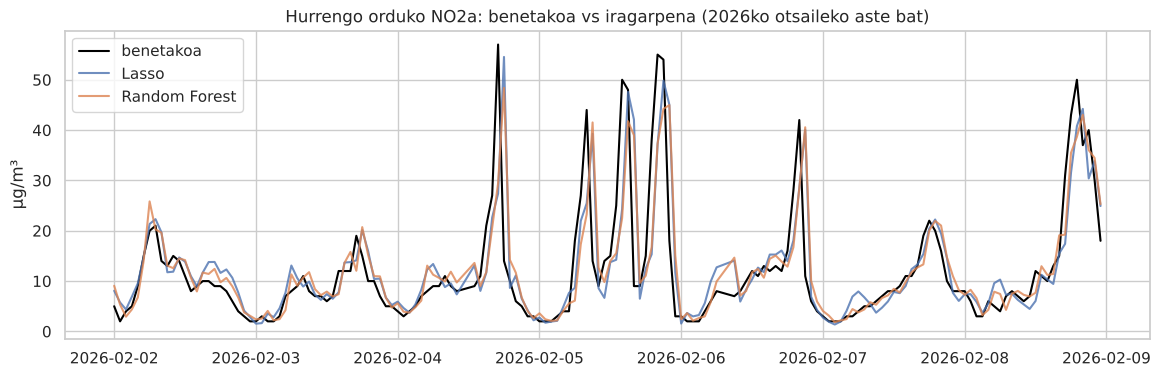

In [ ]:
#2026ko aste bat: benetako balioa eta iragarpenak
astea = proba.loc["2026-02-02":"2026-02-08"]
plt.figure(figsize=(14, 4))
plt.plot(astea.index, astea[ERREGRESIO_HELBURUA], color="black", label="benetakoa")
plt.plot(astea.index, lasso_bilaketa.predict(astea[ALDAGAIAK]), label="Lasso", alpha=0.8)
plt.plot(astea.index, rf_eredua.predict(astea[ALDAGAIAK]), label="Random Forest", alpha=0.8)
plt.title("Hurrengo orduko NO2a: benetakoa vs iragarpena (2026ko otsaileko aste bat)")
plt.ylabel("µg/m³")
plt.legend()
plt.show()

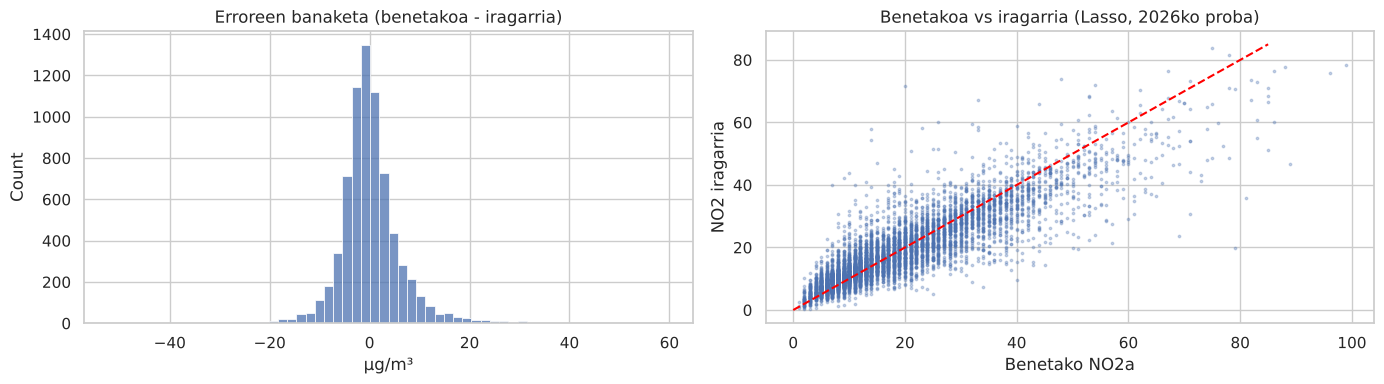

In [19]:
# Lasso ereduaren erroreak (hondarrak)
hondarrak = y_proba - lasso_iragarpena

fig, ardatzak = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(hondarrak, bins=60, ax=ardatzak[0])
ardatzak[0].set_title("Erroreen banaketa (benetakoa - iragarria)")
ardatzak[0].set_xlabel("µg/m³")
ardatzak[1].scatter(y_proba, lasso_iragarpena, s=3, alpha=0.3)
ardatzak[1].plot([0, 85], [0, 85], color="red", linestyle="--")
ardatzak[1].set_xlabel("Benetako NO2a")
ardatzak[1].set_ylabel("NO2 iragarria")
ardatzak[1].set_title("Benetakoa vs iragarria (Lasso, 2026ko proba)")
plt.tight_layout()
plt.show()

In [20]:
# Errorea NO2 mailaren arabera: gailurrak dira garrantzitsuenak alertetarako
mailak = pd.cut(y_proba, bins=[0, 20, 40, 60, 100], labels=["0-20", "20-40", "40-60", ">60"])
erroreak = pd.DataFrame({"maila": mailak, "errorea": hondarrak, "errore_absolutua": hondarrak.abs()})
laburpena = erroreak.groupby("maila", observed=True).agg(orduak=("errorea", "size"),
                                                         MAE=("errore_absolutua", "mean"),
                                                         batez_besteko_errorea=("errorea", "mean"))
laburpena.round(2)

,orduak,MAE,batez_besteko_errorea
maila,,,
0-20,4792,3.22,-1.69
20-40,1947,5.18,2.14
40-60,428,8.95,7.11
>60,86,16.59,15.72


#### Arriskuak

| Arriskua | Neurria |
|---|---|
| Datu-ihesa | Hurrengo ordua iragarri, sarrerek iragana bakarrik erabiltzen dute |
| Balioztapen baikorra | TimeSeriesSplit eta proba = 2026 |
| Gaindoitzea | Entrenamendua eta proba alderatu; erregularizazioa |
| Gailurrak gutxiestea | NO2 > 60 denean ereduak 16 µg/m³ inguru labur geratzen da; sistema adituak ez du iragarpenaren mende bakarrik egon behar |
| Datuen aldaketa | 2026an probako errorea (4,2) balioztapenekoa (4,0) baino apur bat handiagoa da; urtero berrentrenatu |

## 9. Kutsatzaile bakoitzaren erregresioa

Barakaldok ez du O3 neurtzen; beraz, prozesu bera PM10 eta PM2.5ekin errepikatzen dugu. Helbururik gabeko orduak kentzen dira (2023ko PM10ak hutsune asko ditu).

In [ ]:
kutsatzaile_ereduak = {
    "Lineal anizkoitza": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"eredua__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "Lasso": (Lasso(max_iter=10000), {"eredua__alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1]}),
}

errenkadak = []
ridge_kurbak = {}
for kutsatzailea, helburua in KUTSATZAILE_HELBURUAK.items():
    entr_datuak = entrenamendua.dropna(subset=[helburua])
    proba_datuak = proba.dropna(subset=[helburua])

    # Erreferentzia: iraunkortasuna
    iraunkortasuna_k = proba_datuak[kutsatzailea].fillna(entr_datuak[kutsatzailea].median())
    mae, rmse, r2 = metrikak(proba_datuak[helburua], iraunkortasuna_k)
    errenkadak.append([kutsatzailea, "Iraunkortasuna", len(entr_datuak), np.nan, np.nan, mae, rmse, r2, np.nan])

    for izena, (eredua, parametroak) in kutsatzaile_ereduak.items():
        pipeline_k = Pipeline([
            ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
            ("eredua", eredua),
        ])
        if parametroak:
            doikuntza = GridSearchCV(pipeline_k, parametroak, cv=balioztapena, scoring="neg_mean_absolute_error")
            doikuntza.fit(entr_datuak[ALDAGAIAK], entr_datuak[helburua])
            balioztapen_mae = -doikuntza.best_score_
            alpha_onena = doikuntza.best_params_["eredua__alpha"]
            onena = doikuntza.best_estimator_
            if izena == "Ridge":
                ridge_kurbak[kutsatzailea] = -doikuntza.cv_results_["mean_test_score"]
        else:
            balioztapen_mae = -cross_validate(pipeline_k, entr_datuak[ALDAGAIAK], entr_datuak[helburua],
                                              cv=balioztapena, scoring="neg_mean_absolute_error")["test_score"].mean()
            alpha_onena = np.nan
            onena = pipeline_k.fit(entr_datuak[ALDAGAIAK], entr_datuak[helburua])
        mae, rmse, r2 = metrikak(proba_datuak[helburua], onena.predict(proba_datuak[ALDAGAIAK]))
        erabilitako_zutabeak = (onena.named_steps["eredua"].coef_ != 0).sum() if izena == "Lasso" else len(onena.named_steps["eredua"].coef_)
        errenkadak.append([kutsatzailea, izena, len(entr_datuak), alpha_onena, balioztapen_mae, mae, rmse, r2, erabilitako_zutabeak])

kutsatzaile_taula = pd.DataFrame(errenkadak, columns=["kutsatzailea", "eredua", "entrenamenduko orduak", "alpha","balioztapen MAE", "proba MAE", "proba RMSE", "proba R2", "erabilitako zutabeak"])
kutsatzaile_taula.round(3)

,kutsatzailea,eredua,entrenamenduko orduak,alpha,balioztapen MAE,proba MAE,proba RMSE,proba R2,erabilitako zutabeak
0,NO2,Iraunkortasuna,26039,NaN,NaN,4.554,7.010,0.712,NaN
1,NO2,Lineal anizkoitza,26039,NaN,4.012,4.263,6.314,0.766,65.0
2,NO2,Ridge,26039,100.00,3.985,4.255,6.315,0.766,65.0
3,NO2,Lasso,26039,0.01,3.977,4.242,6.314,0.766,51.0
4,PM10,Iraunkortasuna,21233,NaN,NaN,4.663,6.671,0.768,NaN
5,PM10,Lineal anizkoitza,21233,NaN,4.363,4.238,5.926,0.817,65.0
6,PM10,Ridge,21233,100.00,4.214,4.243,5.937,0.816,65.0
7,PM10,Lasso,21233,0.10,4.067,4.298,6.043,0.809,13.0
8,PM25,Iraunkortasuna,25395,NaN,NaN,3.855,5.436,0.472,NaN
9,PM25,Lineal anizkoitza,25395,NaN,3.114,3.246,4.485,0.641,65.0


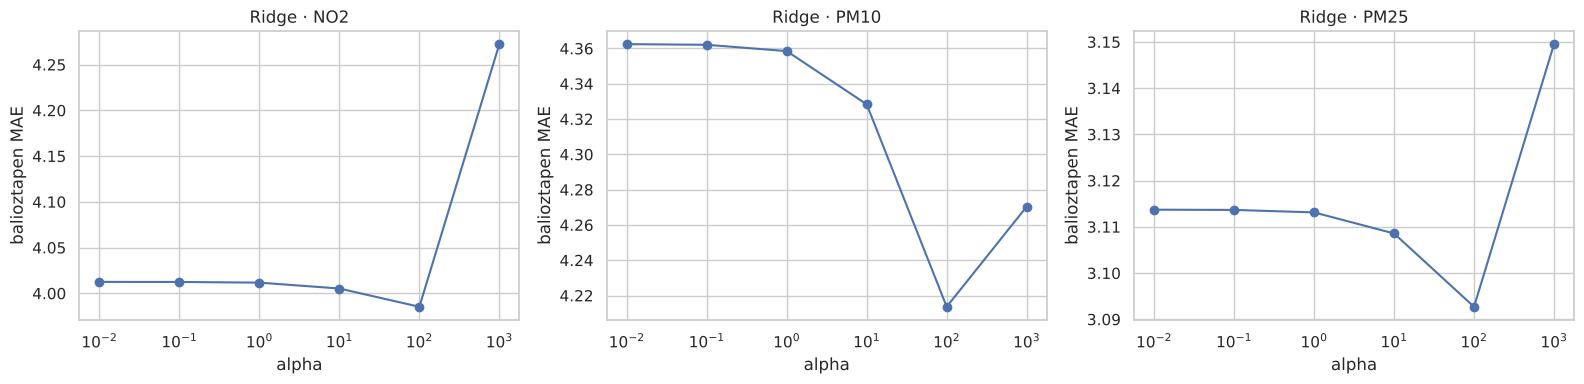

In [22]:
# Erregularizazioaren (Ridge) eragina kutsatzaile bakoitzean
alpha_balioak = [0.01, 0.1, 1, 10, 100, 1000]
fig, ardatzak = plt.subplots(1, 3, figsize=(16, 4))
for ardatza, kutsatzailea in zip(ardatzak, ridge_kurbak):
    ardatza.plot(alpha_balioak, ridge_kurbak[kutsatzailea], marker="o")
    ardatza.set_xscale("log")
    ardatza.set_title("Ridge · " + kutsatzailea)
    ardatza.set_xlabel("alpha")
    ardatza.set_ylabel("balioztapen MAE")
plt.tight_layout()
plt.show()

In [23]:
# Eredu lineal onenaren hobekuntza iraunkortasunaren aldean, kutsatzaile bakoitzean
laburpena = []
for kutsatzailea in KUTSATZAILE_HELBURUAK:
    errenkadak_k = kutsatzaile_taula[kutsatzaile_taula["kutsatzailea"] == kutsatzailea]
    iraun = errenkadak_k[errenkadak_k["eredua"] == "Iraunkortasuna"].iloc[0]
    onena = errenkadak_k[errenkadak_k["eredua"] != "Iraunkortasuna"].sort_values("balioztapen MAE").iloc[0]
    laburpena.append([kutsatzailea, onena["eredua"], iraun["proba MAE"], onena["proba MAE"],
                      100 * (iraun["proba MAE"] - onena["proba MAE"]) / iraun["proba MAE"],
                      iraun["proba R2"], onena["proba R2"]])
pd.DataFrame(laburpena, columns=["kutsatzailea", "onena balioztapenean", "iraunkortasunaren MAE", "ereduaren MAE",
                                 "% errore gutxiago", "iraunkortasunaren R2", "ereduaren R2"]).round(3)

,kutsatzailea,onena balioztapenean,iraunkortasunaren MAE,ereduaren MAE,% errore gutxiago,iraunkortasunaren R2,ereduaren R2
0,NO2,Lasso,4.554,4.242,6.851,0.712,0.766
1,PM10,Lasso,4.663,4.298,7.828,0.768,0.809
2,PM25,Lasso,3.855,3.245,15.824,0.472,0.640


#### Ondorioak

- Pipeline berak balio du hiru kutsatzaileetarako; helburua bakarrik aldatzen da.
- PM2.5ean laguntzen du gehien ereduak: iraunkortasunaren errorea % 16 murrizten du eta R² 0,47tik 0,64ra igotzen. PM10ean % 8 eta NO2an % 7.
- Lasso da onena balioztapenean hiru kutsatzaileetan, nahiz eta proban aldeak oso txikiak diren.

## 10. Ondorioak

| Eredua | Proba MAE | R² |
|---|---|---|
| Iraunkortasuna | 4,55 | 0,71 |
| Lineal sinplea | 4,52 | 0,73 |
| Lineal anizkoitza | 4,26 | 0,77 |
| Ridge | 4,26 | 0,77 |
| Lasso | 4,24 | 0,77 |
| Random Forest | 4,21 | 0,76 |

Eredu anizkoitzek iraunkortasuna % 7 hobetzen dute, eta Random Forestaren ia berdinak dira: orduak one-hot bidez kodetuta, eredu lineal batek ere ikasten ditu puntako orduak.

Lasso aukeratzen dugu: onena da balioztapenean (MAE 3,977), proban Random Forestaren % 1 barruan dago (4,24 / 4,21), sinpleena da (65 zutabeetatik 51 erabiltzen ditu) eta ez du gaindoitzen. Eredu lineala denez, koefizienteekin azal daiteke eta arina da Jetsonerako. Hurrengo moduluetarako gordetzen dugu; MIAn sare neuronal batekin alderatzen da.

In [24]:
joblib.dump(lasso_bilaketa.best_estimator_, "../ereduak/erregresio_onena_lasso.joblib")
taula.to_csv("../docs/emaitzak_erregresioa.csv", index=False)
kutsatzaile_taula.to_csv("../docs/emaitzak_erregresioa_kutsatzaileak.csv", index=False)
print("Gordeta: ereduak/erregresio_onena_lasso.joblib, docs/emaitzak_erregresioa.csv eta docs/emaitzak_erregresioa_kutsatzaileak.csv")

Gordeta: ereduak/erregresio_onena_lasso.joblib, docs/emaitzak_erregresioa.csv eta docs/emaitzak_erregresioa_kutsatzaileak.csv
